# 03 · Training the CNN (on a Kaggle GPU)
Training runs as a private Kaggle kernel, because it needs a GPU:

```bash
python kaggle/build_kernel.py train --user <kaggle-username>  # bundles src/ + splits/split.csv
kaggle kernels push -p kaggle/build/train                     # runs `python -m src.train` on a GPU
kaggle kernels output <user>/skin-lesion-triage-train -p models
```

Recipe (`src/train.py`): EfficientNet-B0 (timm, ImageNet weights), 224×224, flips +
90° rotations + `RandomResizedCrop(0.7–1.0)` + light colour jitter, weighted cross-entropy
with `w = 1/sqrt(class_freq)`, 2 epochs head-only (lr 1e-3), then 12 epochs full fine-tune
with AdamW (1e-4 backbone / 3e-4 head) on a one-cycle cosine schedule, mixed precision.
The checkpoint with the best **validation balanced accuracy** is kept.

**Why weighted CE over a weighted sampler?** The sampler would show the 115 `df` images
~60× per epoch and overfit them; `1/sqrt(freq)` weights rebalance the loss more gently.

In [1]:
import json
import matplotlib.pyplot as plt
import pandas as pd

log = json.load(open("../models/train_log.json"))
h = pd.DataFrame(log["history"])
print("device:", log["device"], "| torch", log["torch"], "| best val balanced accuracy:", round(log["best_val_bacc"], 4))
h

device: cuda | torch 2.11.0+cu130 | best val balanced accuracy: 0.6757


,epoch,phase,train_loss,val_bacc
0,0,head,2.794084,0.292163
1,1,head,2.085250,0.361722
2,2,full,1.702591,0.472731
3,3,full,1.116844,0.576592
4,4,full,0.806266,0.593270
5,5,full,0.644368,0.607399
6,6,full,0.535935,0.636839
7,7,full,0.466086,0.636039
8,8,full,0.401052,0.675714
9,9,full,0.364519,0.661036


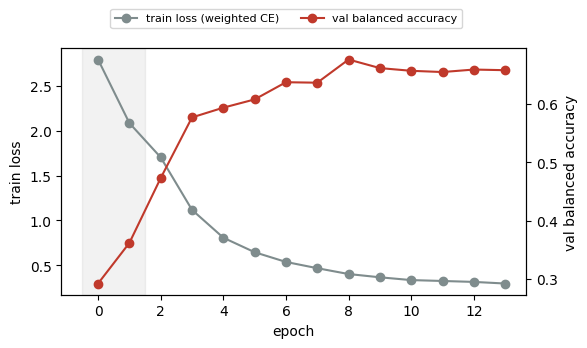

In [2]:
fig, ax1 = plt.subplots(figsize=(6, 3.2))
ax1.plot(h.epoch, h.train_loss, "o-", c="#7f8c8d", label="train loss (weighted CE)")
ax1.set_xlabel("epoch"); ax1.set_ylabel("train loss")
ax2 = ax1.twinx()
ax2.plot(h.epoch, h.val_bacc, "o-", c="#c0392b", label="val balanced accuracy")
ax2.set_ylabel("val balanced accuracy")
ax1.axvspan(-0.5, (h.phase == "head").sum() - 0.5, color="gray", alpha=.1)
fig.legend(loc="upper center", ncol=2, fontsize=8, bbox_to_anchor=(.5, 1.02))
fig.savefig("../figures/training_curve.png", bbox_inches="tight")